# 12 · How long does Lazuli need to detect He I 10830 Å emission on a Sun-like star: with the IFS, or with a new 5 nm WCC filter?

He I 10830 Å traces chromospheric activity (and, in transit, escaping atmospheres; arXiv:1711.05269). A G2V star, V = 3–15 (Johnson, Vega), shows an unresolved emission line at 10830 Å: **FWHM 0.1 Å, peak = continuum, EW = 106 mÅ**. Including the star's photon noise, we compute the exposure time to reach **S/N = 5** on the line, and the S/N of a **10-minute emission event**, for

- the **IFS** (`slicersim`, R ≈ 100), and
- the **WCC with a hypothetical 5 nm top-hat filter** at 10830 Å on the **qCMOS (HWK4123)** (`wcc_etc` `qcmos:` noise model).

The notebook closes with a light curve adapted from WCC tutorial 05.

**Code:** `slicersim` (`LazuliTarget`, MACC `change_detector`); `wcc_etc` (`from_sensorfilter("qcmos:z")` + `set_sensor` on a top-hat throughput, `get_scene("emission", host=...)`). Off the hub: `bash lazuli/install_lazuli_env.sh`.

## Prompt to try in Jupyter AI

> A G2V star (V = 3–15) shows a He I 10830 Å emission line, FWHM 0.1 Å, peak = continuum.
> (1) IFS: with `slicersim.LazuliTarget`, bin-integrate the line onto the IFS wavelength grid, measure it over ±1 LSF FWHM, and find the exposure time to S/N = 5 with unsaturated MACC ramps.
> (2) WCC: build a 5 nm top hat at 10830 Å from the `qcmos:z` throughput, rebuild the sensor on it (`get_sensor_config` + `set_sensor`), verify it, and find the time to S/N = 5 with `get_scene("emission", lines=[...], host="G2V")` in both qCMOS gain modes.
> Plot time to S/N = 5 and the saturation limits versus V, and a light curve with a 10-minute event. State the continuum assumption.

## Setup

Two traps, both tested below: slicersim samples a custom spectrum only at the IFS bin centres, so the 0.1 Å line is integrated over each bin first (gallery notebook 06); and `wcc_etc`'s `update_sensor` does not rebuild the bandpass, so the qCMOS sensor is rebuilt on the top-hat throughput.

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if os.path.isdir(SRC) and not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory (off the hub, sncosmo's default is kept)
if os.path.isdir(DEST):
    os.environ['SNCOSMO_DATA_DIR'] = DEST

import tempfile
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import astropy.units as u
import matplotlib.pyplot as plt
from scipy.special import erf
import slicersim
import wcc_etc
from wcc_etc import Simulation, get_scene, get_sensor_config
from wcc_etc.io import expand_path

print('slicersim', slicersim.__version__, '| wcc_etc', wcc_etc.__version__)
warnings.filterwarnings('ignore', message='spectrum')    # line-only spectra do not cover the whole filter (WCC exercise 4)
trapezoid = getattr(np, 'trapezoid', None) or np.trapz

def fmt_t(t):
    if not np.isfinite(t):
        return 'saturated'
    for lim, div, unit in ((120, 1, 's'), (7200, 60, 'min'), (2 * 86400, 3600, 'h')):
        if t < lim:
            return f"{t / div:.3g} {unit}" if t < 1 else f"{t / div:.1f} {unit}"
    return f"{t / 86400:.1f} d"

def crossing(x, y, level):
    # first x at which y crosses level (interpolated in log y)
    ok = np.isfinite(y)
    x, ly = x[ok], np.log(y[ok])
    k = np.flatnonzero(np.diff(np.sign(ly - np.log(level))) != 0)[0]
    return x[k] + (np.log(level) - ly[k]) * (x[k + 1] - x[k]) / (ly[k + 1] - ly[k])

THUMB = Path('thumbs/12_he10830_ifs_vs_wcc.png')
LINE_WAVE = 10830.0        # Å, He I triplet (air)
LINE_FWHM = 0.1            # Å, intrinsic
LINE_PEAK = 1.0            # line peak / continuum
EW_REF = LINE_PEAK * LINE_FWHM * np.sqrt(np.pi / (4 * np.log(2)))     # Å; Gaussian EW = 1.0645 x FWHM x peak
SNR_TARGET = 5.0
EVENT = 600.0              # s, emission event (sections 5-6)
STAR = 'G2V'
MAG_BAND, MAG_SYS = 'johnson_v', 'vegamag'
FILTER_WIDTH = 50.0        # Å, top hat
BASE_LABEL = 'qcmos:z'     # HWK4123 qCMOS in z': telescope x QE at 1.08 µm, and the sensor noise model
V_GRID = np.arange(3.0, 15.01, 0.25)
V0 = 18.0                  # normalisation magnitude; faint end of the saturation search
print(f"line: FWHM {LINE_FWHM} Å, peak {LINE_PEAK} x continuum, EW = {EW_REF * 1e3:.0f} mÅ")

slicersim 1.4.2 | wcc_etc 0.1.1
line: FWHM 0.1 Å, peak 1.0 x continuum, EW = 106 mÅ


## 1. Star and line

One spectrum for both instruments: the `wcc_etc` G2V Pickles template, normalised in V and passed to slicersim as absolute flux. $F_\mathrm{line} = \mathrm{EW}\,F_\lambda^\mathrm{cont}$, with the continuum averaged over the 50 Å filter window.

In [2]:
LAM = np.arange(3000.0, 20000.0, 1.0)

def star_scene(v, **kw):
    return get_scene(STAR, mag=float(v), bandpass=MAG_BAND, magsys=MAG_SYS, **kw)

def template_flam(scene):
    _, flam = scene.source.get_spectrum(as_array=True, wave=LAM * u.AA, flux_unit='flam')
    return np.asarray(getattr(flam, 'value', flam), dtype=float)

FLAM_V0 = template_flam(star_scene(V0))          # erg/s/cm2/Å at V = V0
assert np.all(np.isfinite(FLAM_V0)) and np.all(FLAM_V0 > 0), 'the G2V template does not cover 3000-20000 Å'
IN_BAND = np.abs(LAM - LINE_WAVE) <= FILTER_WIDTH / 2
FCONT_V0 = FLAM_V0[IN_BAND].mean()

def scale(v):
    return 10 ** (-0.4 * (np.asarray(v) - V0))

def fcont(v):
    return FCONT_V0 * scale(v)                # erg/s/cm2/Å under the line

def line_flux(v, ew=EW_REF):
    return ew * fcont(v)                      # erg/s/cm2

f_z = template_flam(get_scene(STAR, mag=V0, bandpass='sdss_z', magsys='abmag'))[IN_BAND].mean()
print(f"V = {V0:g}: continuum {FCONT_V0:.3e} erg/s/cm2/Å, line {line_flux(V0):.3e} erg/s/cm2; V - z'(AB) = {2.5 * np.log10(FCONT_V0 / f_z):.2f}")

V = 18: continuum 8.132e-17 erg/s/cm2/Å, line 8.656e-18 erg/s/cm2; V - z'(AB) = 1.04


## 2. IFS

Point source, narrow field. The H4RG is read up the ramp ($t_\mathrm{frame}$ = 2.83 s); an exposure is $N$ identical MACC ramps, short for bright stars and long for faint ones (read noise is paid per ramp). Line signal = (star + line) − star over ±1 LSF FWHM; noise from the variance of star + line, so the stellar and line photon noise are included. **The continuum is assumed known** (e.g. from line-free exposures; a single equal-length reference costs √2). Every magnitude and ramp is simulated directly: slicersim's extracted-spectrum noise is not linear enough in flux for a calibrate-once shortcut (7 % off over 6 mag).

In [3]:
probe = slicersim.LazuliTarget(LAM, FLAM_V0)
LB = probe.simulation.spectrograph.lbda
EDGES = np.r_[LB[0] - (LB[1] - LB[0]) / 2, (LB[1:] + LB[:-1]) / 2, LB[-1] + (LB[-1] - LB[-2]) / 2]
IDX = np.searchsorted(EDGES, LAM)              # label i <-> IFS bin between EDGES[i-1] and EDGES[i]
NB = len(EDGES) + 1
SIG_LINE = LINE_FWHM / (2 * np.sqrt(2 * np.log(2)))

def bin_average(flux):
    mean = np.bincount(IDX, flux, minlength=NB) / np.maximum(np.bincount(IDX, minlength=NB), 1)
    return mean[IDX]

def line_per_bin(F):
    # Gaussian line of total flux F integrated exactly over each IFS bin -> bin-mean flux density
    cdf = 0.5 * (1 + erf((EDGES - LINE_WAVE) / (np.sqrt(2) * SIG_LINE)))
    return np.r_[0.0, F * np.diff(cdf) / np.diff(EDGES), 0.0]

def line_binned(F):
    return line_per_bin(F)[IDX]                 # constant within each IFS bin

STAR_BINNED = bin_average(FLAM_V0)
assert np.isclose(np.sum(line_per_bin(1.0)[1:-1] * np.diff(EDGES)), 1.0), 'line flux not conserved'

lr, R = probe.simulation.get_resolving_power()
R_LINE = np.interp(LINE_WAVE, lr, R)
FWHM_LSF = LINE_WAVE / R_LINE
DL = np.gradient(LB)
WIN = np.abs(LB - LINE_WAVE) <= FWHM_LSF
TFRAME = probe.get_properties('tframe')
RAMPS = [(2, 1, 0), (3, 1, 0), (7, 1, 0), (21, 1, 0), (64, 1, 0), (64, 4, 0), (64, 8, 0)]   # MACC (n, m, d), short first
print(f"R = {R_LINE:.0f} at {LINE_WAVE:.0f} Å: LSF FWHM {FWHM_LSF:.0f} Å ({FWHM_LSF / LINE_FWHM:.0f}x the line), "
      f"{np.interp(LINE_WAVE, LB, DL):.0f} Å bins, window {WIN.sum()} bins; t_frame {TFRAME} s")
print("ramps:", ", ".join(f"{nmd} {(nmd[0] * (nmd[1] + nmd[2]) - nmd[2]) * TFRAME:.1f} s" for nmd in RAMPS))

R = 102 at 10830 Å: LSF FWHM 107 Å (1065x the line), 46 Å bins, window 5 bins; t_frame 2.83 s
ramps: (2, 1, 0) 5.7 s, (3, 1, 0) 8.5 s, (7, 1, 0) 19.8 s, (21, 1, 0) 59.4 s, (64, 1, 0) 181.1 s, (64, 4, 0) 724.5 s, (64, 8, 0) 1449.0 s


In [4]:
def ifs_run(flux, nmd, nramps=1):
    # noise-free spectrum, its variance (flambda), saturation flag, exposure time
    t = slicersim.LazuliTarget(LAM, flux)
    t.change_detector(nmd=nmd, nramps=nramps)
    _, f, v = t.get_spectrum(unit='flambda', incl_error=False)
    return f, v, bool(t.simulation.detector.nsaturated_detpx), t.get_exposure_time()

def wsum(v):
    return np.sum(v[WIN] * DL[WIN] ** 2)

def ifs_snr(v, nmd, nramps=1):
    # line S/N, saturation flag, exposure time; star at V = v
    F = line_flux(v)
    f_c, _, sat, t = ifs_run(STAR_BINNED * scale(v), nmd, nramps)
    f_l, v_l, _, _ = ifs_run(STAR_BINNED * scale(v) + line_binned(F), nmd, nramps)
    return np.sum((f_l - f_c)[WIN] * DL[WIN]) / np.sqrt(wsum(v_l)), sat, t

TRAMP = {nmd: ifs_run(STAR_BINNED, nmd)[3] for nmd in RAMPS}
f_c, *_ = ifs_run(STAR_BINNED, RAMPS[3])
f_l, *_ = ifs_run(STAR_BINNED + line_binned(line_flux(V0)), RAMPS[3])
print(f"line flux inside the ±1 FWHM window: {np.sum((f_l - f_c)[WIN] * DL[WIN]) / line_flux(V0):.0%}")

s1, s9 = ifs_snr(13.0, (21, 1, 0), 1)[0], ifs_snr(13.0, (21, 1, 0), 9)[0]
print(f"sqrt(N) check at V = 13: 3 x S/N(1 ramp) = {3 * s1:.3f}, S/N(9 ramps) = {s9:.3f}")
assert np.isclose(s9, 3 * s1, rtol=0.02)

line flux inside the ±1 FWHM window: 98%


sqrt(N) check at V = 13: 3 x S/N(1 ramp) = 1.651, S/N(9 ramps) = 1.651


Bright limit of each ramp by bisection in V (first saturated detector pixel, as in gallery notebook 07). At each V: the ramp minimising $N\,t_\mathrm{ramp}$ with $N = \lceil (5/\mathrm{S/N}_\mathrm{ramp})^2 \rceil$, and, for the 10-minute event, the ramp maximising S/N over the whole ramps that fit.

In [5]:
def ifs_saturates(v, nmd):
    return ifs_run(STAR_BINNED * scale(v), nmd)[2]

def ifs_bright_limit(nmd, lo=2.0, hi=V0, tol=0.05):
    if not ifs_saturates(lo, nmd):
        return lo
    while hi - lo > tol:                         # lo saturates, hi does not
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if ifs_saturates(mid, nmd) else (lo, mid)
    return hi

IFS_SAT = {nmd: ifs_bright_limit(nmd) for nmd in RAMPS}
print("unsaturated for V >", ", ".join(f"{vs:.2f} {nmd}" for nmd, vs in IFS_SAT.items()))

ifs_t5 = np.full(V_GRID.size, np.nan)
ifs_choice = [None] * V_GRID.size                # (ramp, N, S/N reached)
ifs_snr10 = np.full(V_GRID.size, np.nan)
ifs_choice10 = [None] * V_GRID.size              # (ramp, N in 10 min)
for i, v in enumerate(V_GRID):
    best = None
    for nmd in RAMPS:
        if v <= IFS_SAT[nmd]:
            continue
        s1 = ifs_snr(v, nmd)[0]
        N = int(np.ceil((SNR_TARGET / s1) ** 2))
        if best is None or N * TRAMP[nmd] < best[0]:
            best = (N * TRAMP[nmd], nmd, N, s1 * np.sqrt(N))
        n10 = int(EVENT // TRAMP[nmd])
        if n10 >= 1 and not s1 * np.sqrt(n10) <= ifs_snr10[i]:
            ifs_snr10[i], ifs_choice10[i] = s1 * np.sqrt(n10), (nmd, n10)
    if best:
        ifs_t5[i], ifs_choice[i] = best[0], best[1:]

unsaturated for V > 8.88 (2, 1, 0), 9.62 (3, 1, 0), 10.81 (7, 1, 0), 12.12 (21, 1, 0), 13.38 (64, 1, 0), 14.88 (64, 4, 0), 15.62 (64, 8, 0)


## 3. WCC: a 5 nm top hat on the qCMOS (HWK4123)

The new total throughput is the `qcmos:z` curve (telescope × z′ filter × HWK4123 QE) inside 10805–10855 Å and zero outside, i.e. a top hat with the z′ filter's transmission at 1.08 µm. Silicon QE is falling steeply there. The sensor model is unchanged, and both gain modes are run: **high** (read noise 0.5 e⁻ incl. the config's 2× margin, 12-bit ADC clip at 552 e⁻) and **low** (4.66 e⁻, 7500 e⁻ well); minimum frame 8 ms.

qcmos:z: throughput 0.0028 at 10830 Å (peak 0.194); min frame 0.008 s
  high gain: read noise 0.50 electron / pix, saturation 552 electron (adc), dark 0.05 electron / (pix s)
  low  gain: read noise 4.66 electron / pix, saturation 7500 electron (well), dark 0.05 electron / (pix s)


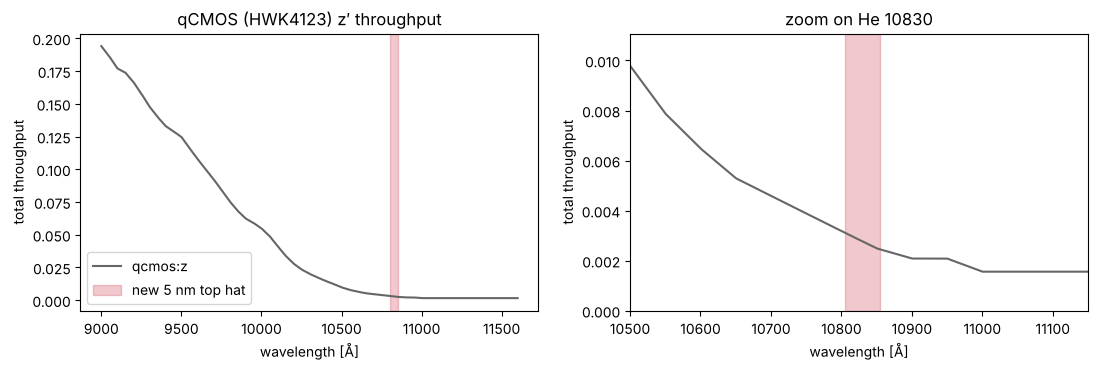

In [6]:
GAIN_MODES = ('high', 'low')
base = Simulation.from_sensorfilter(BASE_LABEL, star_scene(V0))
W = np.arange(9000.0, 11600.0, 0.1)
T_base = base.sensor.bandpass(W).value
T_LINE = float(base.sensor.bandpass(LINE_WAVE).value)
MIN_FRAME = float(base.sensor.meta.get('min_frame_time', 0.008))
if not T_LINE > 1e-5:
    raise RuntimeError(f"{BASE_LABEL} throughput is ~0 at {LINE_WAVE} Å: the shipped curve does not reach He 10830.")
print(f"{BASE_LABEL}: throughput {T_LINE:.4f} at {LINE_WAVE:.0f} Å (peak {T_base.max():.3f}); min frame {MIN_FRAME} s")
for gm in GAIN_MODES:
    sen = Simulation.from_sensorfilter(BASE_LABEL, star_scene(V0), gain_mode=gm).sensor
    print(f"  {gm:4s} gain: read noise {sen.read_noise:.2f}, saturation {sen.saturation_e:.0f} ({sen.saturation_limit}), dark {sen.dark_current}")

fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 3.6))
for a in (ax, bx):
    a.plot(W, T_base, color='0.4', label=BASE_LABEL)
    a.axvspan(LINE_WAVE - FILTER_WIDTH / 2, LINE_WAVE + FILTER_WIDTH / 2, color='#d1495b', alpha=0.3, label='new 5 nm top hat')
    a.set(xlabel='wavelength [Å]', ylabel='total throughput')
bx.set(xlim=(10500, 11150), ylim=(0, 4 * T_LINE), title='zoom on He 10830')
ax.set(title='qCMOS (HWK4123) z′ throughput')
ax.legend()
plt.show()

Write the top hat in the shipped curve's format (CSV, nm) and rebuild the sensor on it with `set_sensor`, keeping the scene, in-focus Airy PSF (evaluated by `wcc_etc` at the source-weighted wavelength, here ≈ 1.08 µm) and gain mode from `from_sensorfilter`.

In [7]:
orig_path = Path(expand_path(base.sensor.meta['path_total_throughput']))
orig = pd.read_csv(orig_path)
wcol, tcol = orig.columns[:2]
w_file_nm, t_file = orig[wcol].to_numpy(float), orig[tcol].to_numpy(float)
probe_w = W[T_base > 0.2 * T_base.max()]
assert np.allclose(np.interp(probe_w / 10, w_file_nm, t_file), base.sensor.bandpass(probe_w).value, rtol=1e-3, atol=1e-6), \
    f'{orig_path.name} does not match the installed bandpass in nm'

lo, hi = (LINE_WAVE - FILTER_WIDTH / 2) / 10, (LINE_WAVE + FILTER_WIDTH / 2) / 10        # nm
w_new = np.unique(np.r_[w_file_nm[(w_file_nm < lo - 0.1) | (w_file_nm > hi + 0.1)], lo - 1e-4, np.linspace(lo, hi, 101), hi + 1e-4])
t_new = np.where((w_new >= lo) & (w_new <= hi), np.interp(w_new, w_file_nm, t_file), 0.0)
TOPHAT_PATH = Path(tempfile.mkdtemp()) / 'wcc_qcmos_he10830_tophat_throughput.csv'
pd.DataFrame({wcol: w_new, tcol: t_new}).to_csv(TOPHAT_PATH, index=False)

def tophat_sim(scene, gain_mode='high'):
    sim = Simulation.from_sensorfilter(BASE_LABEL, scene, gain_mode=gain_mode)
    cfg = get_sensor_config('qcmos', 'z', gain_mode=gain_mode)['sensor']
    cfg['path_total_throughput'] = str(TOPHAT_PATH)
    sim.set_sensor(cfg)
    return sim

nb = tophat_sim(star_scene(V0))
T_nb = nb.sensor.bandpass(W).value
T_want = np.where(np.abs(W - LINE_WAVE) <= FILTER_WIDTH / 2, T_base, 0.0)
edge = np.abs(np.abs(W - LINE_WAVE) - FILTER_WIDTH / 2) < 0.6
assert np.allclose(T_nb[~edge], T_want[~edge], atol=1e-3 * T_LINE), 'the installed bandpass is not the top hat'
RECT = trapezoid(T_nb, W) / float(nb.sensor.bandpass(LINE_WAVE).value)
print(f"top hat installed: pivot {float(nb.sensor.bandpass.pivot().value):.1f} Å, rectangular width {RECT:.1f} Å")

top hat installed: pivot 10829.0 Å, rectangular width 50.1 Å


Check: a line at 10700 Å (inside z′, outside the top hat) must vanish, and a 0.1 Å line must give the same S/N as a 2 Å one.

In [8]:
def line_scene(F, wave=LINE_WAVE, fwhm=LINE_FWHM, v=None):
    kw = {} if v is None else dict(host=STAR, host_prop={'mag': float(v), 'bandpass': MAG_BAND, 'magsys': MAG_SYS})
    return get_scene('emission', mag=None, lines=[{'wave': wave, 'flux': float(F), 'fwhm': fwhm}], **kw)

def snr_line(scene, t=60.0):
    try:
        return tophat_sim(scene).get_image_snr(t, warn=False)['snr']
    except ValueError as err:                  # wcc_etc refuses a source with no flux in the bandpass
        if 'no positive photon flux' in str(err):
            return 0.0
        raise

s_in, s_out, s_wide = snr_line(line_scene(1e-15)), snr_line(line_scene(1e-15, wave=10700.0)), snr_line(line_scene(1e-15, fwhm=2.0))
print(f"1e-15 erg/s/cm2 line, 60 s: S/N {s_in:.2f} (0.1 Å), {s_wide:.2f} (2 Å), {s_out:.2f} (at 10700 Å)")
assert s_out < 0.01 * s_in, 'the filter is not applied'
assert np.isclose(s_in, s_wide, rtol=0.02), 'the 0.1 Å line is not sampled correctly'

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


1e-15 erg/s/cm2 line, 60 s: S/N 0.48 (0.1 Å), 0.48 (2 Å), 0.00 (at 10700 Å)


The line is the source and the G2V star a point-source host (WCC exercise 4), so `get_image_snr` returns the line S/N including the star's noise. Frames are 80 % of the peak-pixel saturation time, capped at 60 s (gallery notebook 10). With fixed frames every noise term, read noise included, grows linearly with $t$, so $t_5 = 60\,\mathrm{s}\,(5/\mathrm{S/N}_{60})^2$; full runs at $t_5$ check this. The faster gain mode is kept. Cross-check: σ(EW) = star-only precision × filter width.

In [9]:
T_UNIT, FRAME_MAX = 60.0, 60.0

def frame_time(sim):
    # longest frame (<= FRAME_MAX) below 80 % of saturation; None if shorter than the minimum frame
    tf = min(FRAME_MAX, 0.8 * sim.sensor.saturation_e.value / sim.get_peak_pixel(1.0, units='e-').value)
    return None if tf < MIN_FRAME else tf

def n_reads(t, tf):
    return max(1, int(np.ceil(t / tf)))

def set_star(wl, v):
    wl.update(host__mag=float(v))
    wl.update(source__lines=[{'wave': LINE_WAVE, 'flux': float(line_flux(v)), 'fwhm': LINE_FWHM}])

SIMS = {gm: (tophat_sim(line_scene(line_flux(V0), v=V0), gm), tophat_sim(star_scene(V0), gm)) for gm in GAIN_MODES}

def wcc_point(v, gm):
    # (t5, frame time, S/N in 60 s, star-only ppm in 60 s), or None if saturated
    wl, ws = SIMS[gm]
    set_star(wl, v)
    tf = frame_time(wl)
    if tf is None:
        return None
    r = wl.get_image_snr(T_UNIT, n_reads=n_reads(T_UNIT, tf), warn=False)
    if r['saturated']:
        return None
    ws.update(source__mag=float(v))
    ppm = 1e6 / ws.get_image_snr(T_UNIT, n_reads=n_reads(T_UNIT, tf), warn=False)['snr']
    return T_UNIT * (SNR_TARGET / r['snr']) ** 2, tf, r['snr'], ppm

wcc_t5, wcc_snr60, wcc_ppm, wcc_tf = (np.full(V_GRID.size, np.nan) for _ in range(4))
wcc_gain = [None] * V_GRID.size
for i, v in enumerate(V_GRID):
    pts = {gm: p for gm in GAIN_MODES if (p := wcc_point(v, gm)) is not None}
    if pts:
        wcc_gain[i] = min(pts, key=lambda g: pts[g][0])
        wcc_t5[i], wcc_tf[i], wcc_snr60[i], wcc_ppm[i] = pts[wcc_gain[i]]
assert float(SIMS['high'][0].sensor.bandpass(LINE_WAVE + 40).value) < 1e-6, 'update() reverted the filter'
wcc_snr10 = wcc_snr60 * np.sqrt(EVENT / T_UNIT)

for v in (6.0, 12.0):
    i = np.argmin(np.abs(V_GRID - v))
    wl = SIMS[wcc_gain[i]][0]
    set_star(wl, v)
    s5 = wl.get_image_snr(wcc_t5[i], n_reads=n_reads(wcc_t5[i], wcc_tf[i]), warn=False)['snr']
    print(f"V = {v:g}: full run at t5 = {fmt_t(wcc_t5[i])} gives S/N {s5:.2f}")
    assert np.isclose(s5, SNR_TARGET, rtol=0.03)
ratio = (EW_REF / wcc_snr60) / (wcc_ppm * 1e-6 * RECT)
print(f"sigma_EW / (star-only precision x {RECT:.1f} Å) = {np.nanmedian(ratio):.3f}")
assert 0.9 < np.nanmedian(ratio) < 1.1
print("gain mode chosen:", {gm: f"V = {min(vs):g}-{max(vs):g}" for gm in GAIN_MODES if (vs := [v for v, g in zip(V_GRID, wcc_gain) if g == gm])})

V = 6: full run at t5 = 4.0 min gives S/N 5.00
V = 12: full run at t5 = 17.1 h gives S/N 5.00
sigma_EW / (star-only precision x 50.1 Å) = 0.999
gain mode chosen: {'high': 'V = 3-15'}


## 4. Saturation

Longest unsaturated single exposure. WCC: frame time from the peak pixel, both gains. IFS: ramp integration $(n-1)(m+d)\,t_\mathrm{frame}$, scaled from each ramp's bisected limit (section 2); the signal is linear in time, so all ramps fall on one curve. The IFS's shortest ramp integrates one 2.83 s frame while the qCMOS can read every 8 ms, so the IFS stops at V ≈ 9 although its pixels fill only slightly faster.

IFS: the 7 ramps agree on the saturation time to 1 %


    V |   IFS ramp |   WCC high    WCC low
  3.0 |   0.0127 s |   0.0216 s    0.293 s
  5.0 |     0.08 s |    0.136 s      1.8 s
  7.0 |    0.505 s |    0.858 s     11.7 s
  9.0 |      3.2 s |      5.4 s     73.5 s
 11.0 |     20.1 s |     34.1 s    7.7 min
 13.0 |    2.1 min |    3.5 min   47.9 min
 15.0 |   13.3 min |   20.2 min      4.6 h


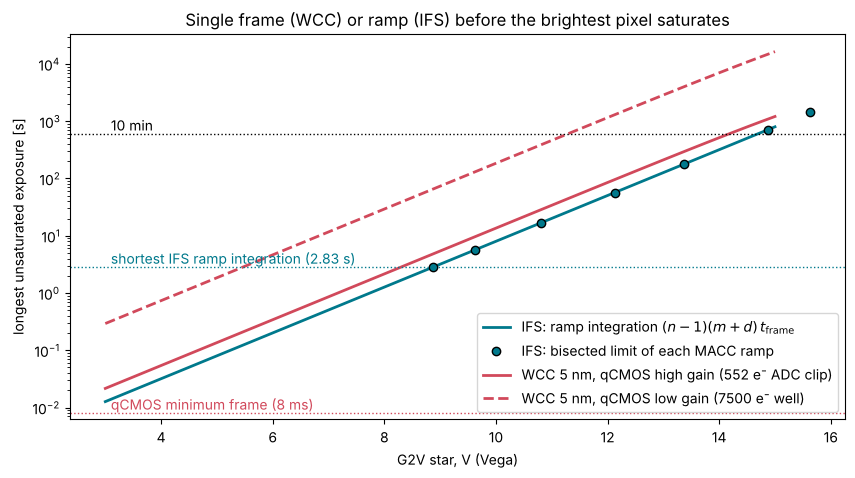

In [10]:
IFS_TINT = {nmd: (nmd[0] - 1) * (nmd[1] + nmd[2]) * TFRAME for nmd in RAMPS}
est = np.array([[IFS_TINT[nmd] * 10 ** (0.4 * (v - IFS_SAT[nmd])) for nmd in RAMPS] for v in V_GRID])
ifs_tsat = np.exp(np.log(est).mean(axis=1))
print(f"IFS: the {len(RAMPS)} ramps agree on the saturation time to {100 * (est.max(axis=1) / est.min(axis=1) - 1).max():.0f} %")
assert (est.max(axis=1) / est.min(axis=1)).max() < 1.15

wcc_tsat = {gm: np.full(V_GRID.size, np.nan) for gm in GAIN_MODES}
for gm in GAIN_MODES:
    wl = SIMS[gm][0]
    for i, v in enumerate(V_GRID):
        set_star(wl, v)
        wcc_tsat[gm][i] = wl.sensor.saturation_e.value / wl.get_peak_pixel(1.0, units='e-').value
used = np.array([g == 'high' for g in wcc_gain])
assert np.allclose(wcc_tf[used], np.minimum(FRAME_MAX, 0.8 * wcc_tsat['high'][used]), rtol=1e-6)

print(f"{'V':>5} | {'IFS ramp':>10} | {'WCC high':>10} {'WCC low':>10}")
for vv in (3, 5, 7, 9, 11, 13, 15):
    i = np.argmin(np.abs(V_GRID - vv))
    print(f"{vv:5.1f} | {fmt_t(ifs_tsat[i]):>10} | {fmt_t(wcc_tsat['high'][i]):>10} {fmt_t(wcc_tsat['low'][i]):>10}")

c_ifs, c_wcc = '#00798c', '#d1495b'
fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogy(V_GRID, ifs_tsat, '-', color=c_ifs, lw=2, label='IFS: ramp integration $(n-1)(m+d)\\,t_\\mathrm{frame}$')
ax.semilogy([IFS_SAT[n] for n in RAMPS], [IFS_TINT[n] for n in RAMPS], 'o', color=c_ifs, mec='k', label='IFS: bisected limit of each MACC ramp')
ax.semilogy(V_GRID, wcc_tsat['high'], '-', color=c_wcc, lw=2, label='WCC 5 nm, qCMOS high gain (552 e⁻ ADC clip)')
ax.semilogy(V_GRID, wcc_tsat['low'], '--', color=c_wcc, lw=2, label='WCC 5 nm, qCMOS low gain (7500 e⁻ well)')
for t, lab, c in ((IFS_TINT[RAMPS[0]], 'shortest IFS ramp integration (2.83 s)', c_ifs), (MIN_FRAME, 'qCMOS minimum frame (8 ms)', c_wcc), (EVENT, '10 min', 'k')):
    ax.axhline(t, color=c, ls=':', lw=1)
    ax.text(V_GRID[0] + 0.1, t * 1.15, lab, color=c, fontsize=10)
ax.set(xlabel='G2V star, V (Vega)', ylabel='longest unsaturated exposure [s]',
       title='Single frame (WCC) or ramp (IFS) before the brightest pixel saturates')
ax.legend(loc='lower right', fontsize=10)
plt.show()

## 5. Comparison

Time to S/N = 5, and S/N in a 10-minute event. Photon-limited, $t \propto \mathrm{EW}^{-2}$.

In [11]:
print(f"{'':>5} | {'IFS':^41} | {'WCC 5 nm filter':^42} |")
print(f"{'V':>5} | {'t(S/N=5)':>10} {'ramps':>18} {'S/N 10 min':>11} | {'t(S/N=5)':>10} {'gain':>4} {'frame':>9} {'S/N 10 min':>11} | {'WCC/IFS':>7}")
for vv in (3, 4, 6, 8, 9, 10, 12, 14, 15):
    i = np.argmin(np.abs(V_GRID - vv))
    c = ifs_choice[i]
    ramps = f"{c[1]} x {c[0]}" if c else ''
    fr = f"{wcc_tf[i]:.3g} s" if np.isfinite(wcc_tf[i]) else ''
    print(f"{vv:5.1f} | {fmt_t(ifs_t5[i]):>10} {ramps:>18} {ifs_snr10[i]:11.1f} | {fmt_t(wcc_t5[i]):>10} {wcc_gain[i] or '':>4} {fr:>9} {wcc_snr10[i]:11.1f} | {wcc_t5[i] / ifs_t5[i]:7.1f}")
for name, snr10 in (('IFS', ifs_snr10), ('WCC 5 nm', wcc_snr10)):
    print(f"{name}: S/N >= {SNR_TARGET:g} in a 10-minute event for V = {V_GRID[np.isfinite(snr10)][0]:g} to {crossing(V_GRID, snr10, SNR_TARGET):.2f}")

      |                    IFS                    |              WCC 5 nm filter               |
    V |   t(S/N=5)              ramps  S/N 10 min |   t(S/N=5) gain     frame  S/N 10 min | WCC/IFS
  3.0 |  saturated                            nan |     15.2 s high  0.0172 s        31.4 |     nan
  4.0 |  saturated                            nan |     38.2 s high  0.0433 s        19.8 |     nan
  6.0 |  saturated                            nan |    4.0 min high   0.273 s         7.9 |     nan
  8.0 |  saturated                            nan |   25.3 min high    1.72 s         3.1 |     nan
  9.0 |    3.5 min     37 x (2, 1, 0)         8.5 |   63.7 min high    4.33 s         2.0 |    18.2
 10.0 |    6.7 min     47 x (3, 1, 0)         6.2 |      2.7 h high    10.9 s         1.2 |    24.1
 12.0 |   34.7 min    105 x (7, 1, 0)         2.7 |     17.1 h high      60 s         0.5 |    29.7
 14.0 |      3.4 h    68 x (64, 1, 0)         1.1 |      5.0 d high      60 s         0.2 |    35.2
 15

## 6. Light curve with a 10-minute event (after WCC tutorial 05)

Line EW = 0 except during a 10-minute event; back-to-back 10-minute exposures (IFS: whole ramps, 9.9 min), the event filling one. IFS star V = 10, WCC star V = 5, each in its usable range. White noise only, as in tutorial 05. In narrowband relative flux the event is $1 + \mathrm{EW}/W_\mathrm{rect}$.

In [12]:
V_DEMO = {'IFS': 10.0, 'WCC 5 nm (qCMOS)': 5.0}
k_exp = np.arange(-15, 16)                       # 10-minute exposures; the event fills exposure 0
ew_true = np.where(k_exp == 0, EW_REF, 0.0)
rng = np.random.default_rng(3)
LC = {}
for name, v in V_DEMO.items():
    i = np.argmin(np.abs(V_GRID - v))
    if name == 'IFS':
        c10 = ifs_choice10[i]
        s, how = ifs_snr10[i], f"{c10[1]} x {c10[0]} = {c10[1] * TRAMP[c10[0]] / 60:.1f} min"
    else:
        s, how = wcc_snr10[i], f"{wcc_gain[i]} gain, {wcc_tf[i]:.3g} s frames"
    sig = EW_REF / s
    LC[name] = (k_exp * EVENT / 60, ew_true + rng.normal(0, sig, k_exp.size), sig, v)
    print(f"{name:18s} V = {v:g} ({how}): sigma_EW {sig * 1e3:.1f} mÅ, event at {s:.1f} sigma")
print(f"narrowband event amplitude: 1 + {EW_REF / RECT * 1e6:.0f} ppm")

IFS                V = 10 (70 x (3, 1, 0) = 9.9 min): sigma_EW 17.3 mÅ, event at 6.2 sigma
WCC 5 nm (qCMOS)   V = 5 (high gain, 0.109 s frames): sigma_EW 8.5 mÅ, event at 12.5 sigma
narrowband event amplitude: 1 + 2124 ppm


**Check: curve vs light curves.** S/N ∝ √t, so the 10-minute S/N is $5\sqrt{10\,\mathrm{min}/t_5}$: above 5 below the dashed line of the main plot (12.5 for the WCC at V = 5, where $t_5$ = 1.6 min) and 5 where the curve crosses it. Tested against fresh 10-minute simulations.

In [13]:
for name, v in V_DEMO.items():
    i = np.argmin(np.abs(V_GRID - v))
    if name == 'IFS':
        nmd, n10 = ifs_choice10[i]
        t10, t5, snr_t5 = n10 * TRAMP[nmd], ifs_t5[i], ifs_choice[i][2]     # whole ramps: S/N at t5 is >= 5
        direct, lc = ifs_snr(v, nmd, n10)[0], ifs_snr10[i]
    else:
        t10, t5, snr_t5 = EVENT, wcc_t5[i], SNR_TARGET
        sim = tophat_sim(line_scene(line_flux(v), v=v), wcc_gain[i])
        direct, lc = sim.get_image_snr(t10, n_reads=n_reads(t10, frame_time(sim)), warn=False)['snr'], wcc_snr10[i]
    from_curve = snr_t5 * np.sqrt(t10 / t5)
    print(f"{name:18s} V = {v:g}: from the curve {snr_t5:.2f} x sqrt({t10:.0f} s / {t5:.0f} s) = {from_curve:.2f}; "
          f"light curve {lc:.2f}; direct simulation {direct:.2f}")
    assert np.isclose(lc, direct, rtol=0.02) and np.isclose(from_curve, direct, rtol=0.03)

for name, t5, s10 in (('IFS', ifs_t5, ifs_snr10), ('WCC 5 nm (qCMOS)', wcc_t5, wcc_snr10)):
    v_t, v_s = crossing(V_GRID, t5, EVENT), crossing(V_GRID, s10, SNR_TARGET)
    print(f"{name:18s} t5 = 10 min at V = {v_t:.2f}; 10-minute S/N = 5 at V = {v_s:.2f}")
    assert abs(v_t - v_s) < 0.15

IFS                V = 10: from the curve 5.05 x sqrt(594 s / 399 s) = 6.16; light curve 6.16; direct simulation 6.16
WCC 5 nm (qCMOS)   V = 5: from the curve 5.00 x sqrt(600 s / 96 s) = 12.51; light curve 12.51; direct simulation 12.51
IFS                t5 = 10 min at V = 10.45; 10-minute S/N = 5 at V = 10.44
WCC 5 nm (qCMOS)   t5 = 10 min at V = 6.99; 10-minute S/N = 5 at V = 6.99


## Hero figure

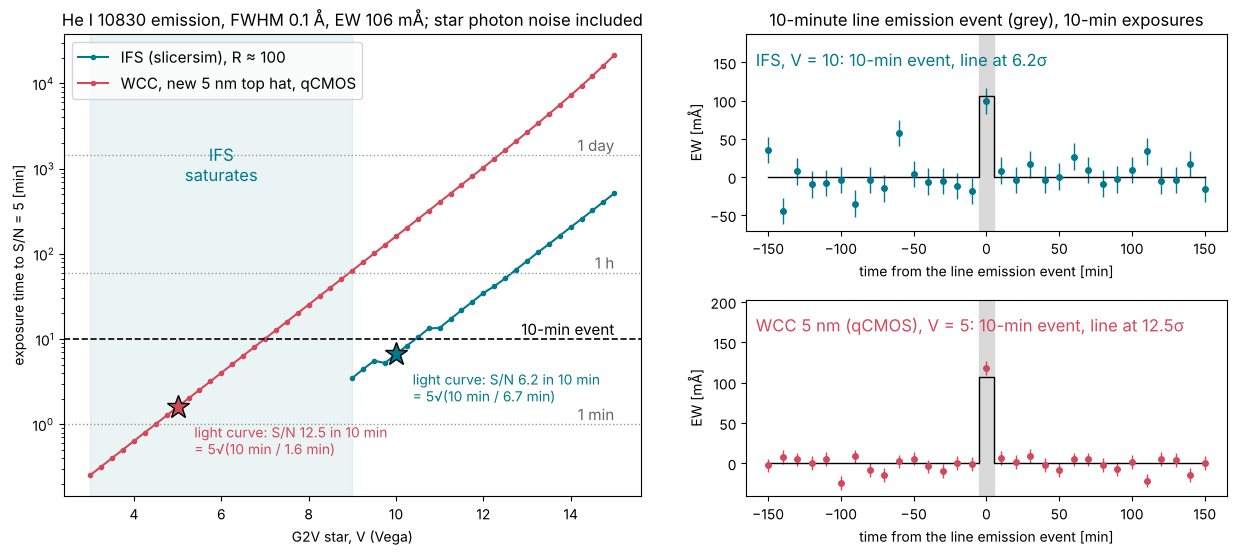

In [14]:
cols = {'IFS': '#00798c', 'WCC 5 nm (qCMOS)': '#d1495b'}
fig = plt.figure(figsize=(15, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1], hspace=0.35)
ax = fig.add_subplot(gs[:, 0])
ax.semilogy(V_GRID, ifs_t5 / 60, 'o-', ms=3, color=cols['IFS'], label='IFS (slicersim), R ≈ 100')
ax.semilogy(V_GRID, wcc_t5 / 60, 'o-', ms=3, color=cols['WCC 5 nm (qCMOS)'], label='WCC, new 5 nm top hat, qCMOS')
for t, lab in ((1, '1 min'), (60, '1 h'), (1440, '1 day')):
    ax.axhline(t, color='0.6', ls=':', lw=1)
    ax.text(V_GRID[-1], t * 1.12, lab, color='0.4', fontsize=11, ha='right')
ax.axhline(EVENT / 60, color='k', ls='--', lw=1.2)
ax.text(V_GRID[-1], EVENT / 60 * 1.12, '10-min event', color='k', fontsize=11, ha='right')
ok = np.isfinite(ifs_t5)
ax.axvspan(V_GRID[0], V_GRID[ok][0], color=cols['IFS'], alpha=0.08)
ax.text(0.5 * (V_GRID[0] + V_GRID[ok][0]), np.nanmax(wcc_t5) / 60 / 30, 'IFS\nsaturates', ha='center', color=cols['IFS'], fontsize=12)
for name, v in V_DEMO.items():
    i = np.argmin(np.abs(V_GRID - v))
    t5, s10 = (ifs_t5[i], ifs_snr10[i]) if name == 'IFS' else (wcc_t5[i], wcc_snr10[i])
    ax.plot(v, t5 / 60, marker='*', ms=17, color=cols[name], mec='k', zorder=5)
    ax.annotate(f"light curve: S/N {s10:.1f} in 10 min\n= 5√(10 min / {t5 / 60:.1f} min)", (v, t5 / 60), xytext=(12, -34),
                textcoords='offset points', fontsize=10, color=cols[name])
ax.set(xlabel='G2V star, V (Vega)', ylabel='exposure time to S/N = 5 [min]',
       title=f'He I 10830 emission, FWHM 0.1 Å, EW {EW_REF * 1e3:.0f} mÅ; star photon noise included')
ax.legend(loc='upper left', fontsize=11)

for k, (name, (t_min, ew, sig, v)) in enumerate(LC.items()):
    bx = fig.add_subplot(gs[k, 1])
    bx.axvspan(-0.5 * EVENT / 60, 0.5 * EVENT / 60, color='0.85', zorder=0)
    bx.errorbar(t_min, ew * 1e3, yerr=sig * 1e3, fmt='o', ms=4, color=cols[name], capsize=0, lw=1)
    bx.step(t_min, ew_true * 1e3, where='mid', color='k', lw=1)
    bx.text(0.02, 0.92, f"{name}, V = {v:g}: 10-min event, line at {EW_REF / sig:.1f}σ", transform=bx.transAxes, va='top', fontsize=12, color=cols[name])
    bx.set_ylim(top=1.6 * max((ew + sig).max(), EW_REF) * 1e3)
    bx.set(ylabel='EW [mÅ]', xlabel='time from the line emission event [min]')
    if k == 0:
        bx.set_title('10-minute line emission event (grey), 10-min exposures')
fig.savefig(THUMB, dpi=150, bbox_inches='tight')
plt.show()

## Answer

G2V star; He I 10830 line with FWHM 0.1 Å and EW 106 mÅ; star photon noise included (slicersim 1.4.2, wcc_etc 0.1.1):

| V | 3 | 6 | 9 | 10 | 12 | 15 |
|---|---|---|---|---|---|---|
| IFS: t(S/N = 5) | saturates | saturates | 3.5 min | 6.7 min | 35 min | 8.6 h |
| WCC 5 nm filter: t(S/N = 5) | 15 s | 4.0 min | 64 min | 2.7 h | 17 h | 15 d |
| S/N in a 10-min event, IFS / WCC | – / 31 | – / 7.9 | 8.5 / 2.0 | 6.2 / 1.2 | 2.7 / 0.5 | 0.7 / 0.1 |

- **The IFS is 18–42× faster wherever it can observe (V ≳ 9).** The qCMOS z′ total throughput at 1.083 µm is only 0.28 %.
- **The filter's niche is V < 9**, which the IFS cannot take. The IFS's shortest ramp integrates one 2.83 s frame, whereas the qCMOS reads out every 8 ms (high gain is better at every V). Per unit time the IFS pixels actually fill slightly faster (3.2 s vs 5.4 s to saturation at V = 9).
- **A 10-minute event reaches S/N ≥ 5 for V = 9–10.4 with the IFS, or V ≤ 7.0 with the WCC filter.** Neither instrument covers V ≈ 7–9.
- The time scales as EW⁻²: a line twice as strong takes a quarter of the time.

## Caveats & next steps

- **Steady line** across the exposure; a shorter event is diluted by its duty cycle.
- **Hypothetical filter:** an ideal 50 Å top hat at the z′ filter's 1.08 µm transmission, on the shipped `qcmos:z` telescope × QE curve. The answer scales with the HWK4123 QE at 1083 nm (check the datasheet); real interference filters lose peak transmission and shift with angle of incidence.
- **Continuum assumed known.** One narrowband filter cannot separate line emission from a continuum change (a white-light flare mimics He I); the IFS measures the adjacent continuum in the same exposure. An off-line WCC filter would fix this, at √2 in noise.
- **Star:** G2V Pickles template, V − z′(AB) = 1.04; a redder star is brighter at 10830 Å for the same V.
- **IFS:** point source in the narrow field; ±1 FWHM box (98 % of the line) against a noise-free continuum; fixed list of MACC ramps.
- **White noise only:** no flat-field, jitter or gain-drift floor, non-linearity or persistence.
- Photospheric Si I 10827 Å lies in the filter but is constant; flare He I broadening or shifts (≲ 1 Å) stay inside both apertures.
- *Next:* off-line filter at 10700 Å; filter width 1–10 nm; an M-dwarf host; the IFS wide field.